# 1. Signals, EMD and the IMF choice (Sec. III-A)

How a noisy ECG is built (`src/data.py`), what the EMD gives (`src/emd.py`), and which IMFs
each noise's adaptive filter should use (`scripts/01_imf_selection.py`).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from src.config import FIGURES_DIR, RESULTS_DIR
pd.set_option("display.precision", 2)

## ECG scaling and noise mix
ECG: zero mean, peak |x| = 1. Noises: NSTDB records in mV (natural ratio), PLI with the power
of BW; the sum is scaled to the requested SNRin.

In [2]:
from src.config import FIG8_RECORDS, FIG10_RECORDS
from src.data import ALL_NOISES, load_ecg, make_case, noise_shares
from src.metrics import snr

print("noise power shares:", {k.upper(): f"{100 * v:.1f} %" for k, v in noise_shares().items()})
print("clean ECG RMS per record:",
      {r: round(float(np.sqrt(np.mean(load_ecg(r) ** 2))), 3) for r in FIG8_RECORDS + FIG10_RECORDS})
case = make_case(100, ALL_NOISES, 0)
print(f"check: SNRin of record 100 at 0 dB = {snr(case['clean'], case['noisy']):.3f} dB")

noise power shares: {'BW': '24.7 %', 'EM': '46.6 %', 'MA': '3.9 %', 'PLI': '24.7 %'}
clean ECG RMS per record: {119: 0.159, 202: 0.14, 213: 0.197, 217: 0.251, 234: 0.154, 100: 0.121, 103: 0.141, 104: 0.144, 105: 0.142, 106: 0.146, 111: 0.159, 113: 0.168, 115: 0.133, 116: 0.17, 121: 0.145, 122: 0.193, 123: 0.111, 231: 0.13}
check: SNRin of record 100 at 0 dB = 0.000 dB


## EMD of a noisy ECG

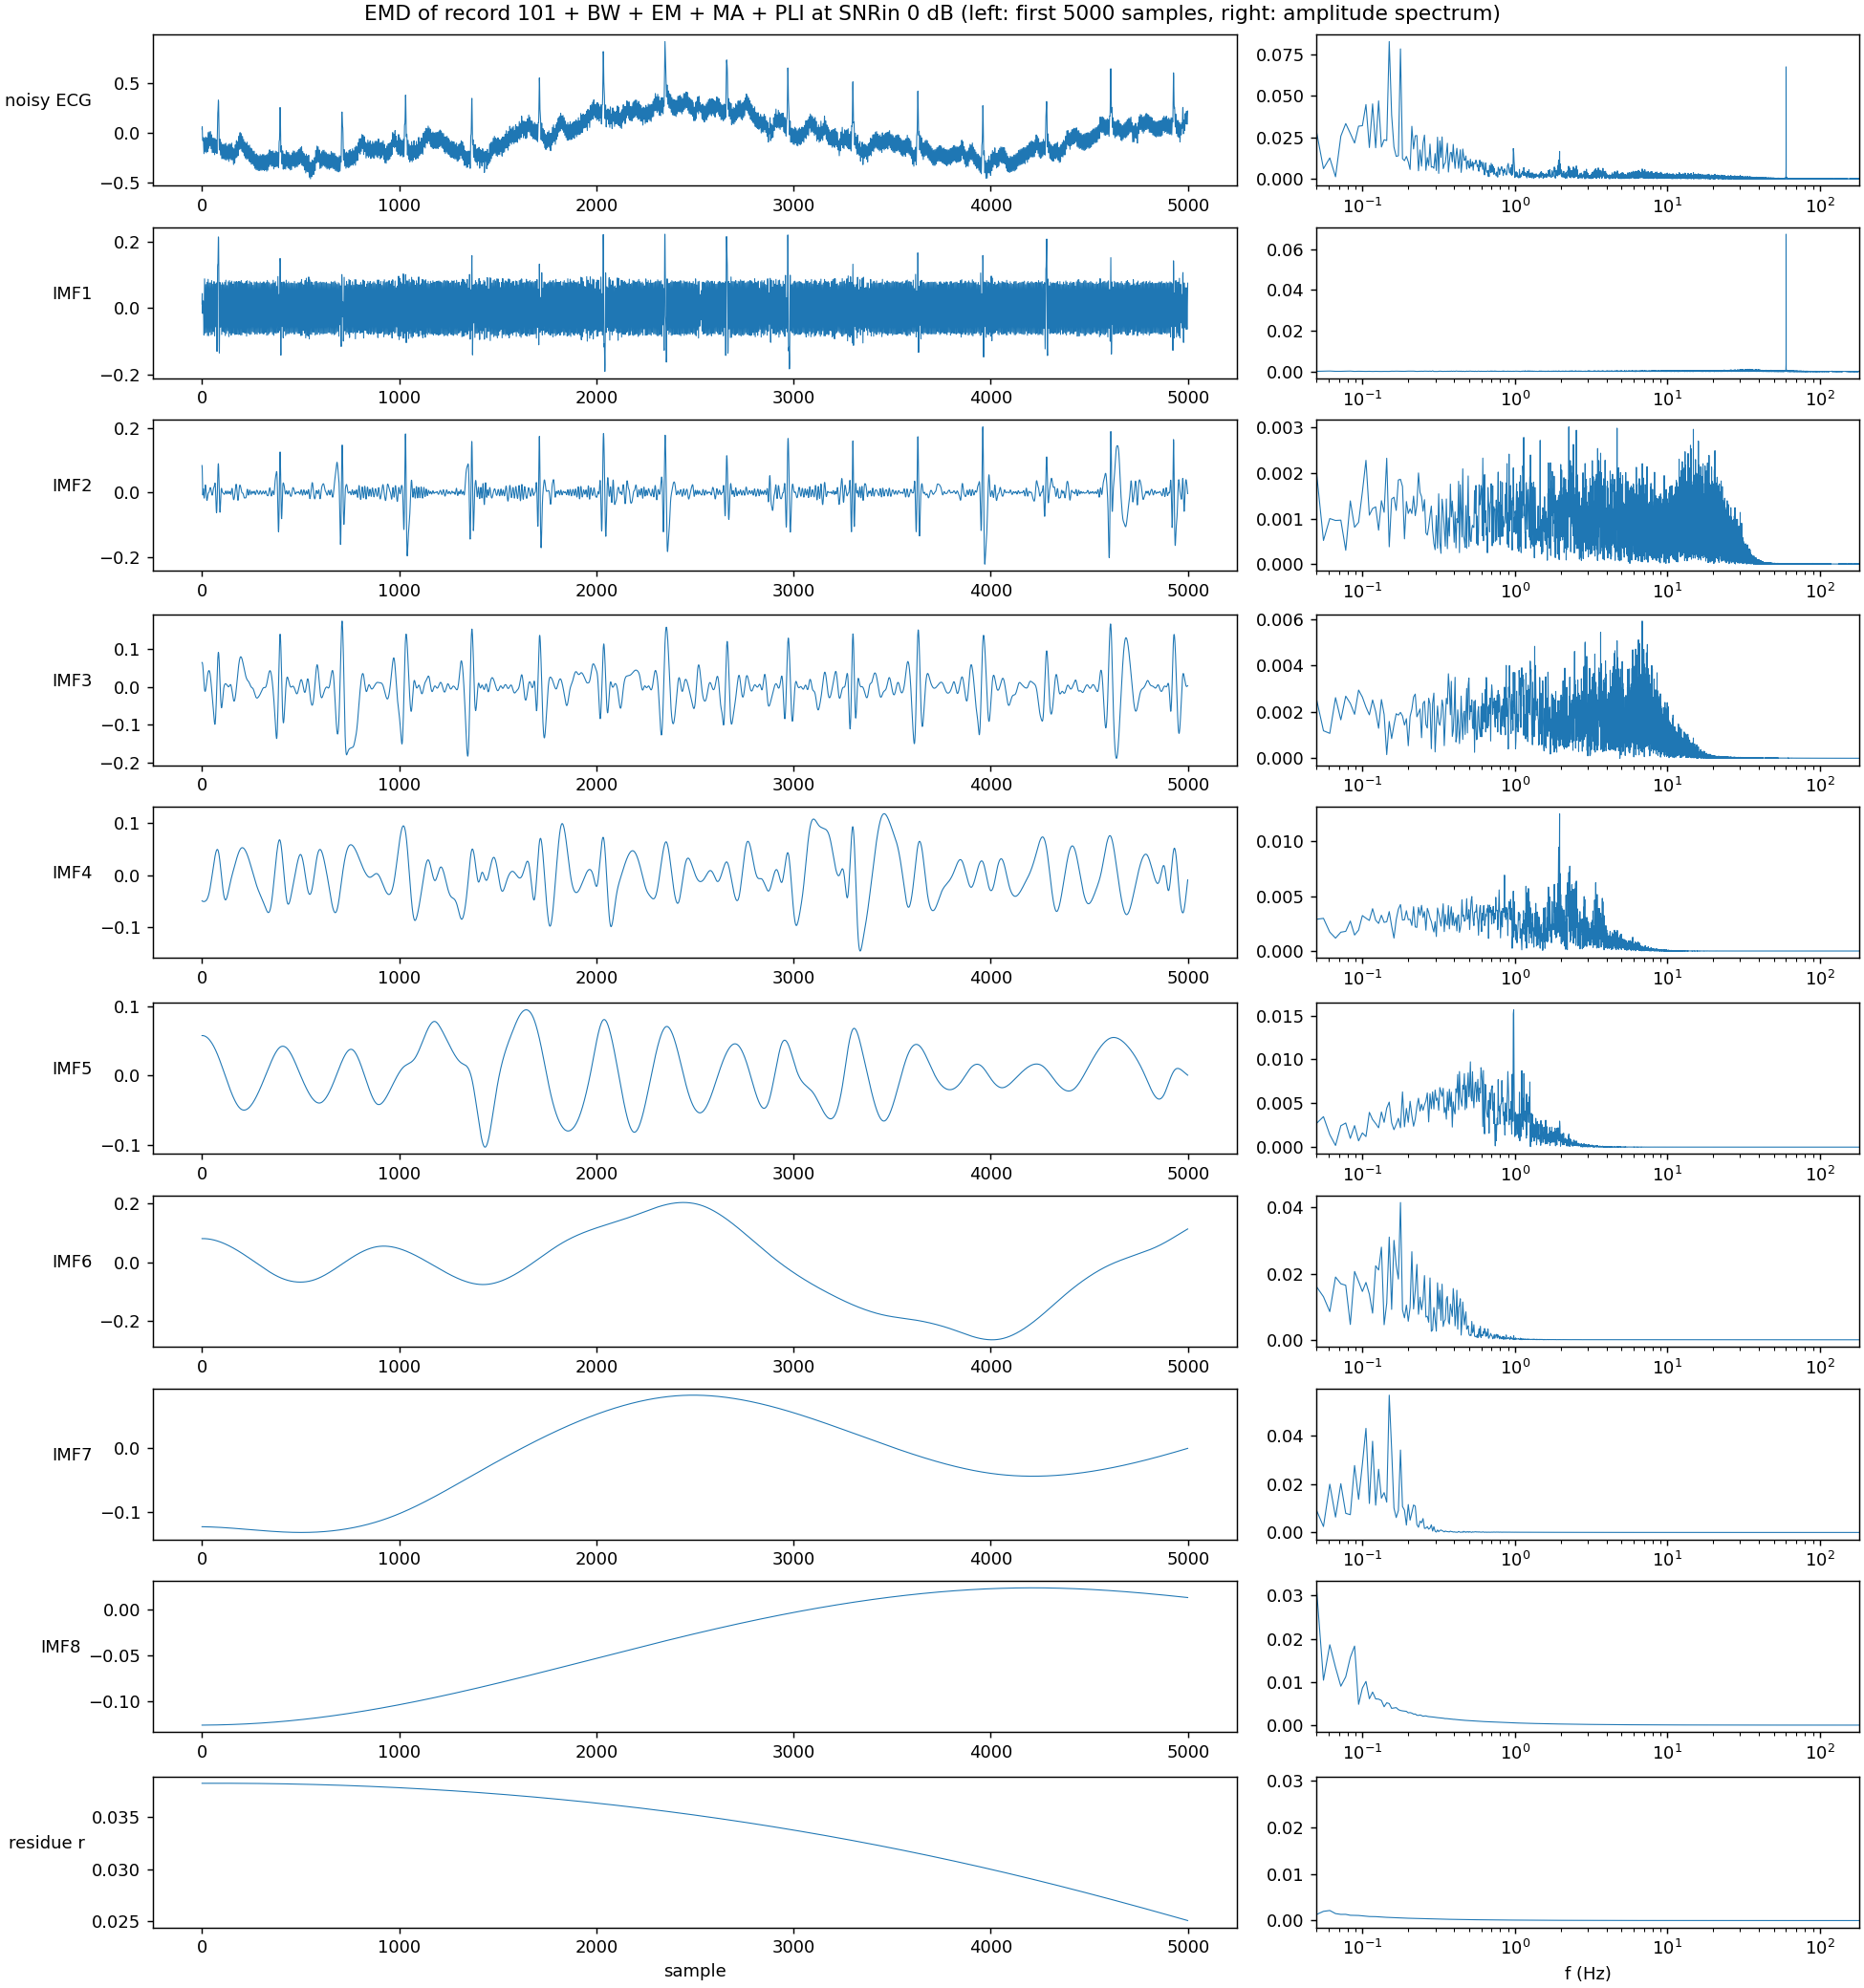

In [3]:
display(Image(FIGURES_DIR / "emd_imfs_and_spectra_of_noisy_ecg.png", width=900))

## Sec. III-A: best IMFs for each noise
Each noise alone, LMS filter on IMFi~IMFj (Fig. 2) at its best setting; mean SNRimp over the
held-out tuning cases. Red box = the paper's choice.

In [4]:
imf = pd.read_csv(RESULTS_DIR / "imf_selection.csv")
best = imf.loc[imf.groupby("noise").mean_SNRimp_dB.idxmax(), ["noise", "imfs", "mean_SNRimp_dB"]]
paper = imf[imf.paper_choice][["noise", "imfs", "mean_SNRimp_dB"]]
best.merge(paper, on="noise", suffixes=(" ours best", " paper's choice")).set_index("noise")

,imfs ours best,mean_SNRimp_dB ours best,imfs paper's choice,mean_SNRimp_dB paper's choice
noise,,,,
bw,no EMD,14.22,IMF5~8,13.88
em,IMF1~8,13.69,IMF3~8,13.45
ma,no EMD,13.47,no EMD,13.47
pli,IMF1,28.98,IMF1,28.98


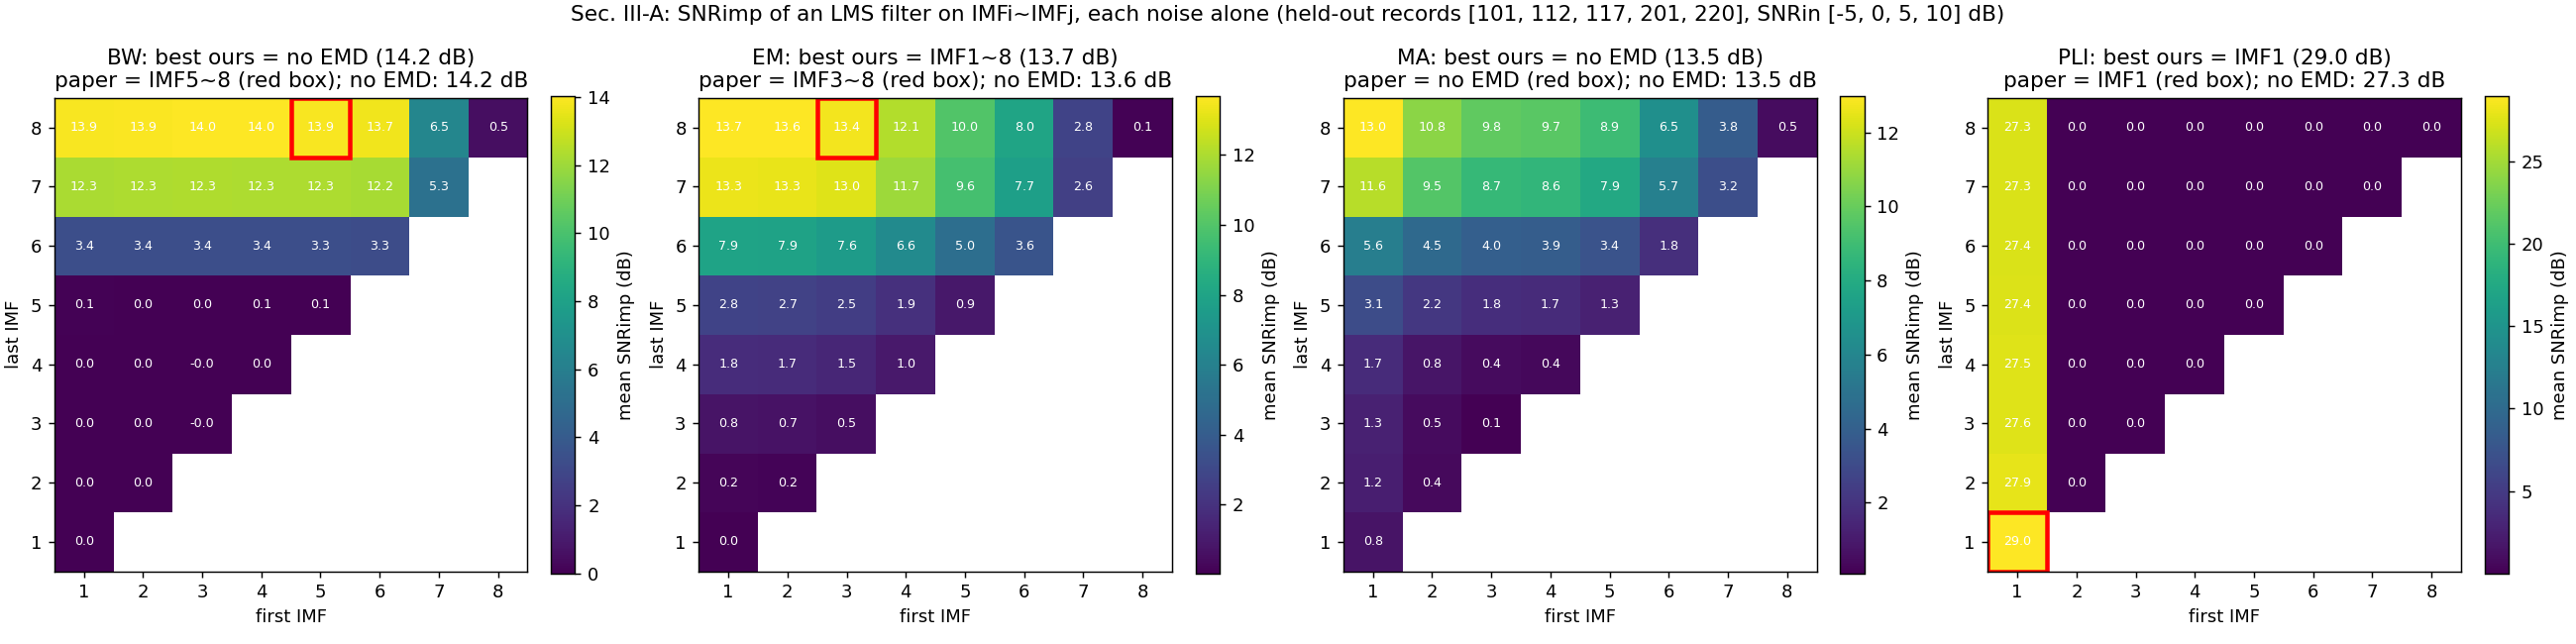

In [5]:
display(Image(FIGURES_DIR / "imf_selection_snr_imp_per_imf_range.png", width=1100))